# Project 1 — Wine Classification

## Dataset Overview

In [1]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

display(X.head())
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())
print("Missing feature values:", X.isna().sum().sum())
print("Missing target values:", y.isna().sum())
print("Samples per class:")
print(y.value_counts().sort_index())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Number of samples: 178
Number of features: 13
Number of classes: 3
Missing feature values: 0
Missing target values: 0
Samples per class:
target
0    59
1    71
2    48
Name: count, dtype: int64


## Training, Validation, and Test Split

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42
)

print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Test samples:", len(y_test))

class_counts = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Test": y_test.value_counts(),
}).sort_index()

display(class_counts)

Training samples: 106
Validation samples: 36
Test samples: 36


,Training,Validation,Test
target,,,
0,35,12,12
1,42,14,15
2,29,10,9


## Feature Scaling

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled training shape: (106, 13)
Scaled validation shape: (36, 13)
Scaled test shape: (36, 13)


## Baseline

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_scaled, y_train)

baseline_val_pred = baseline.predict(X_val_scaled)

print("Most frequent training class:", y_train.mode().iloc[0])
print(f"Baseline validation accuracy: {accuracy_score(y_val, baseline_val_pred):.2%}")

Most frequent training class: 1
Baseline validation accuracy: 38.89%


## Model Comparison

In [5]:
from sklearn.metrics import precision_recall_fscore_support
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC


def evaluate_predictions(actual, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, predicted, average="macro", zero_division=0
    )
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
    }


models = {
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "KNN (k=11)": KNeighborsClassifier(n_neighbors=11),
    "SVM (C=0.1)": SVC(kernel="rbf", C=0.1),
    "SVM (C=1)": SVC(kernel="rbf", C=1),
    "SVM (C=10)": SVC(kernel="rbf", C=10),
}

validation_scores = {
    "Baseline": evaluate_predictions(y_val, baseline_val_pred)
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    val_pred = model.predict(X_val_scaled)
    validation_scores[name] = evaluate_predictions(y_val, val_pred)

results = pd.DataFrame.from_dict(validation_scores, orient="index")
display(results.style.format("{:.2%}"))

,Accuracy,Macro Precision,Macro Recall,Macro F1
Baseline,38.89%,12.96%,33.33%,18.67%
KNN (k=3),88.89%,90.30%,90.48%,89.15%
KNN (k=5),94.44%,94.41%,95.24%,94.52%
KNN (k=11),94.44%,94.41%,95.24%,94.52%
SVM (C=0.1),94.44%,95.83%,93.89%,94.57%
SVM (C=1),100.00%,100.00%,100.00%,100.00%
SVM (C=10),100.00%,100.00%,100.00%,100.00%


## Final Test Results

Selected model: SVM (C=1)
Kernel: rbf
Test Accuracy: 97.22%
Test Macro Precision: 97.92%
Test Macro Recall: 96.30%
Test Macro F1: 96.96%


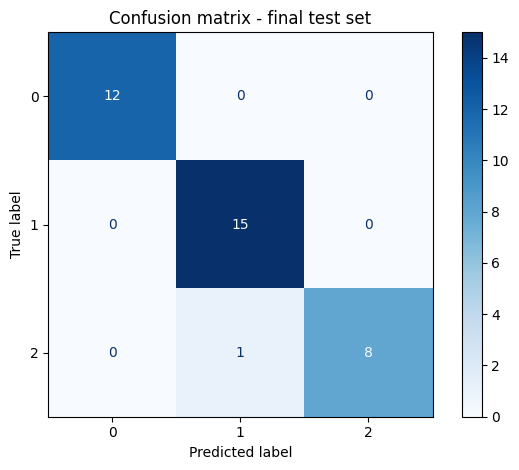

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

selected_name = "SVM (C=1)"
selected_model = models[selected_name]

test_pred = selected_model.predict(X_test_scaled)
test_scores = evaluate_predictions(y_test, test_pred)

print("Selected model:", selected_name)
print("Kernel:", selected_model.kernel)

for metric, score in test_scores.items():
    print(f"Test {metric}: {score:.2%}")

labels = [0, 1, 2]
test_cm = confusion_matrix(y_test, test_pred, labels=labels)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=labels,
).plot(cmap="Blues")

plt.title("Confusion matrix - final test set")
plt.tight_layout()
plt.show()

## Business Recommendation

We recommend piloting the RBF SVM with C=1 to support laboratory sample sorting. It correctly classified 35 of 36 test samples and achieved a macro F1-score of 96.96%. Its only error was assigning one class 2 sample to class 1. Because the test set was small, the laboratory should validate the model on a larger, independent set of samples before relying on it for routine sorting.


1. **Did the model with the highest accuracy also achieve the highest Macro F1?**  
   Yes. On the validation set, the RBF SVM models with `C=1` and `C=10` tied at 100% for both metrics. We selected `C=1` because it applies a lower penalty to training errors.

2. **Why is scaling important?**  
   KNN and RBF SVM use distances between samples. Standardization helps prevent measurements with larger numerical scales from dominating those distances. The scaler was fitted on the training data only.

3. **Which classification errors remain?**  
   The model assigned one true class 2 sample to class 1. All other test samples were classified correctly.

4. **How does the small test set affect confidence?**  
   The test set contains only 36 samples, so each additional error would reduce accuracy by about 2.78 percentage points. The result is promising, but the exact accuracy could change on a larger set of samples.


We recommend piloting the RBF SVM with `C=1` to support laboratory sample sorting. It correctly classified 35 of 36 test samples, achieving 97.22% accuracy and 96.96% Macro F1. Its only error was assigning one class 2 sample to class 1. Because the test set was small, the laboratory should validate the model on a larger, independent set of samples before using it for routine sorting.

# Project 2 — Housing Value Estimation

## Dataset Overview

Saved CSV: california_housing.csv
Number of rows: 20640
Number of features: 8


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
Missing values per column:


,Missing values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Target summary:


,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


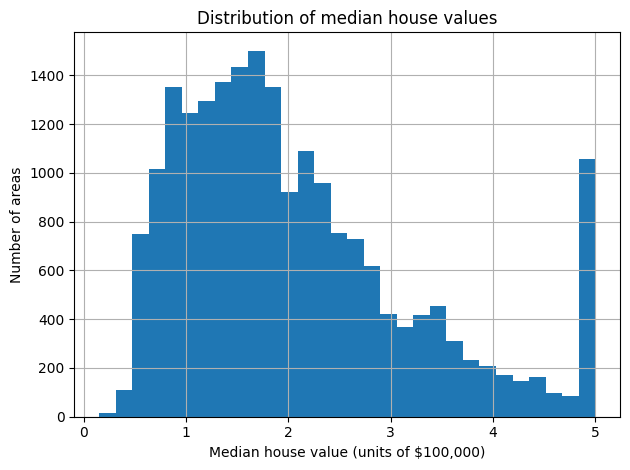

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame

file_name = "california_housing.csv"
df.to_csv(file_name, index=False)

target_column = "MedHouseVal"
X = df.drop(columns=[target_column])
y = df[target_column]

print("Saved CSV:", file_name)
print("Number of rows:", len(df))
print("Number of features:", X.shape[1])

display(df.head())
df.info()

print("Missing values per column:")
display(df.isna().sum().rename("Missing values").to_frame())

print("Target summary:")
display(y.describe())

y.hist(bins=30)
plt.xlabel("Median house value (units of $100,000)")
plt.ylabel("Number of areas")
plt.title("Distribution of median house values")
plt.tight_layout()
plt.show()

## Training, Validation, and Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.40, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=42
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Training rows: 12384
Validation rows: 4128
Test rows: 4128


## Baseline

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_val_pred = baseline.predict(X_val)

baseline_mae = mean_absolute_error(y_val, baseline_val_pred)
baseline_rmse = root_mean_squared_error(y_val, baseline_val_pred)
baseline_r2 = r2_score(y_val, baseline_val_pred)

print(f"Baseline prediction: ${y_train.mean() * 100_000:,.2f}")
print(f"Validation MAE: {baseline_mae:.4f} (${baseline_mae * 100_000:,.2f})")
print(f"Validation RMSE: {baseline_rmse:.4f}")
print(f"Validation R²: {baseline_r2:.4f}")

Baseline prediction: $206,339.67
Validation MAE: 0.9039 ($90,394.05)
Validation RMSE: 1.1425
Validation R²: -0.0001


## Model Comparison

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def evaluate_regression(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": root_mean_squared_error(actual, predicted),
        "R²": r2_score(actual, predicted),
    }


models = {}

for alpha in [0.1, 1, 10]:
    models[f"Ridge (alpha={alpha})"] = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha),
    )

for max_depth in [5, 10, None]:
    models[f"Random Forest (max_depth={max_depth})"] = RandomForestRegressor(
        n_estimators=100,
        max_depth=max_depth,
        random_state=42,
        n_jobs=-1,
    )

validation_scores = {
    "Baseline": evaluate_regression(y_val, baseline_val_pred)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    validation_scores[name] = evaluate_regression(y_val, val_pred)

results = pd.DataFrame.from_dict(validation_scores, orient="index")
results = results.sort_values("RMSE")
display(results.style.format("{:.4f}"))

,MAE,RMSE,R²
Random Forest (max_depth=None),0.3410,0.5163,0.7958
Random Forest (max_depth=10),0.3764,0.5503,0.7680
Random Forest (max_depth=5),0.4972,0.6813,0.6444
Ridge (alpha=10),0.5336,0.7297,0.5921
Ridge (alpha=1),0.5336,0.7298,0.5920
Ridge (alpha=0.1),0.5336,0.7298,0.5920
Baseline,0.9039,1.1425,-0.0001


## Final Test Results and Error Analysis

Selected model: Random Forest (max_depth=None)
Number of trees: 100
Random state: 42
Test MAE: 0.3428 ($34,283.67)
Test RMSE: 0.5235
Test R²: 0.8002

Five largest absolute prediction errors:


,Actual (USD),Predicted (USD),Error (USD),Absolute error (USD)
12069,"$500,001.00","$174,949.00","$-325,052.00","$325,052.00"
13766,"$500,001.00","$178,504.06","$-321,496.94","$321,496.94"
6688,"$500,001.00","$186,907.02","$-313,093.98","$313,093.98"
19542,"$450,000.00","$144,772.00","$-305,228.00","$305,228.00"
15297,"$500,001.00","$196,114.00","$-303,887.00","$303,887.00"


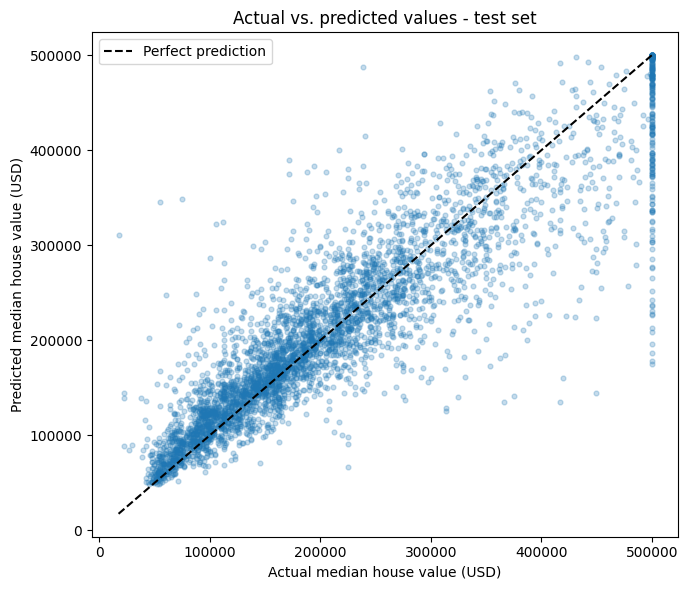

In [ ]:
selected_name = results["RMSE"].idxmin()
selected_model = models[selected_name]

test_pred = selected_model.predict(X_test)
test_scores = evaluate_regression(y_test, test_pred)

print("Selected model:", selected_name)
print("Number of trees:", selected_model.n_estimators)
print("Random state:", selected_model.random_state)
print(f"Test MAE: {test_scores['MAE']:.4f} (${test_scores['MAE'] * 100_000:,.2f})")
print(f"Test RMSE: {test_scores['RMSE']:.4f}")
print(f"Test R²: {test_scores['R²']:.4f}")

actual_usd = y_test * 100_000
predicted_usd = test_pred * 100_000

error_table = pd.DataFrame({
    "Actual (USD)": actual_usd,
    "Predicted (USD)": predicted_usd,
})
error_table["Error (USD)"] = (
    error_table["Predicted (USD)"] - error_table["Actual (USD)"]
)
error_table["Absolute error (USD)"] = error_table["Error (USD)"].abs()

largest_errors = error_table.nlargest(5, "Absolute error (USD)")

print("\nFive largest absolute prediction errors:")
display(largest_errors.style.format("${:,.2f}"))

lower = min(actual_usd.min(), predicted_usd.min())
upper = max(actual_usd.max(), predicted_usd.max())

plt.figure(figsize=(7, 6))
plt.scatter(actual_usd, predicted_usd, alpha=0.25, s=12)
plt.plot([lower, upper], [lower, upper], "--", color="black", label="Perfect prediction")
plt.xlabel("Actual median house value (USD)")
plt.ylabel("Predicted median house value (USD)")
plt.title("Actual vs. predicted values - test set")
plt.legend()
plt.tight_layout()
plt.show()

# Project 3 — Wholesale Customer Segmentation

## Dataset and Spending Patterns

Number of customers: 440
Number of spending features: 6


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


Missing values per column:


,Missing values
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


Spending summary:


,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


Highest spending observations per category:


,Highest,Second highest,Third highest
Fresh,112151,76237,68951
Milk,73498,54259,46197
Grocery,92780,67298,59598
Frozen,60869,36534,35009
Detergents_Paper,40827,38102,26701
Delicassen,47943,16523,14472


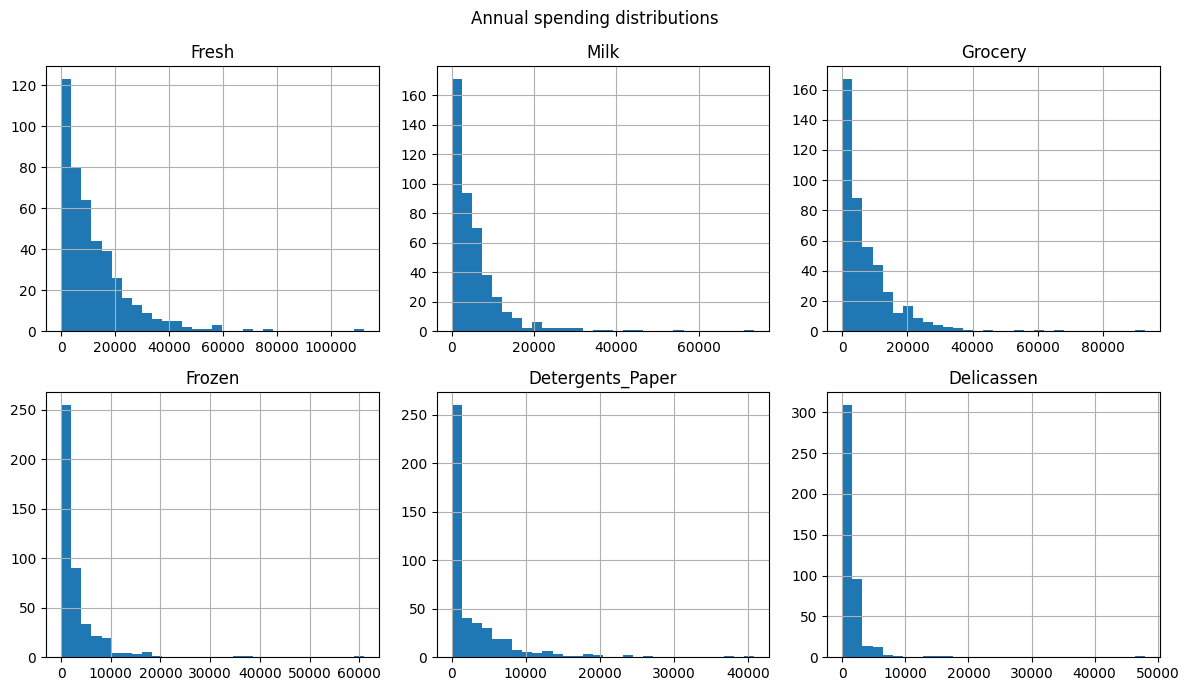

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

data_url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "00292/Wholesale%20customers%20data.csv"
)
df = pd.read_csv(data_url)

spending_columns = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen",
]
X = df[spending_columns].copy()

print("Number of customers:", len(df))
print("Number of spending features:", X.shape[1])
display(df.head())

print("Missing values per column:")
display(df.isna().sum().rename("Missing values").to_frame())

print("Spending summary:")
display(X.describe().T)

print("Highest spending observations per category:")
display(X.apply(lambda column: column.nlargest(3).tolist()).T.rename(
    columns={0: "Highest", 1: "Second highest", 2: "Third highest"}
))

X.hist(bins=30, figsize=(12, 7), layout=(2, 3))
plt.suptitle("Annual spending distributions")
plt.tight_layout()
plt.show()

## Data Preparation

In [2]:
import numpy as np
from sklearn.preprocessing import StandardScaler

X_log = np.log1p(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Prepared data shape:", X_scaled.shape)
print("Column means:", np.round(X_scaled.mean(axis=0), 6))
print("Column standard deviations:", np.round(X_scaled.std(axis=0), 6))

Prepared data shape: (440, 6)
Column means: [ 0. -0. -0.  0. -0. -0.]
Column standard deviations: [1. 1. 1. 1. 1. 1.]


## Clustering Comparison

In [3]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score

experiments = []
cluster_labels = {}

for k in [2, 3, 4, 5]:
    models = {
        "K-Means": KMeans(n_clusters=k, random_state=42, n_init=10),
        "Agglomerative (Ward)": AgglomerativeClustering(
            n_clusters=k, linkage="ward"
        ),
    }

    for name, model in models.items():
        labels = model.fit_predict(X_scaled)
        cluster_labels[(name, k)] = labels

        experiments.append({
            "Algorithm": name,
            "Clusters": k,
            "Silhouette Score": silhouette_score(X_scaled, labels),
            "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels),
        })

results = pd.DataFrame(experiments).sort_values(
    ["Silhouette Score", "Davies-Bouldin Index"],
    ascending=[False, True],
).reset_index(drop=True)

display(results.style.format({
    "Silhouette Score": "{:.4f}",
    "Davies-Bouldin Index": "{:.4f}",
}))

,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index
0,K-Means,2,0.2903,1.3515
1,K-Means,3,0.2594,1.3406
2,Agglomerative (Ward),2,0.2585,1.6004
3,Agglomerative (Ward),3,0.2547,1.5390
4,Agglomerative (Ward),5,0.2025,1.3862
5,Agglomerative (Ward),4,0.2021,1.5211
6,K-Means,5,0.1916,1.4843
7,K-Means,4,0.1885,1.5408


## Selected Model and Cluster Sizes

In [4]:
best_result = results.iloc[0]
selected_algorithm = best_result["Algorithm"]
selected_k = int(best_result["Clusters"])
selected_labels = cluster_labels[(selected_algorithm, selected_k)]

print("Selected algorithm:", selected_algorithm)
print("Number of clusters:", selected_k)
print(f"Silhouette Score: {best_result['Silhouette Score']:.4f}")
print(f"Davies-Bouldin Index: {best_result['Davies-Bouldin Index']:.4f}")

customer_segments = X.assign(Cluster=selected_labels)
grouped = customer_segments.groupby("Cluster")

cluster_sizes = grouped.size().rename("Customers").to_frame()
cluster_sizes["Share"] = cluster_sizes["Customers"] / len(customer_segments)

median_spending = grouped[spending_columns].median()

print("\nCluster sizes:")
display(cluster_sizes.style.format({"Share": "{:.1%}"}))

print("\nMedian annual spending by cluster (original values):")
display(median_spending.style.format("{:,.1f}"))

Selected algorithm: K-Means
Number of clusters: 2
Silhouette Score: 0.2903
Davies-Bouldin Index: 1.3515

Cluster sizes:


,Customers,Share
Cluster,,
0,252,57.3%
1,188,42.7%



Median annual spending by cluster (original values):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,"10,347.5","1,871.0","2,406.0","2,225.0",327.5,749.5
1,"5,406.5","7,690.5","11,527.0","1,061.5","4,495.0","1,388.5"


## Segment Profiles and Visualization

,Segment,Customers,Share,Purchasing characteristics,Proposed offer
Cluster,,,,,
0,Fresh & Frozen Buyers,252,57.3%,Higher median spending on fresh and frozen products.,Volume discount on a combined fresh and frozen order.
1,"Grocery, Milk & Supplies Buyers",188,42.7%,"Higher median spending on grocery, milk, detergents, and paper products.","Bundle discount on grocery, milk, detergents, and paper products."


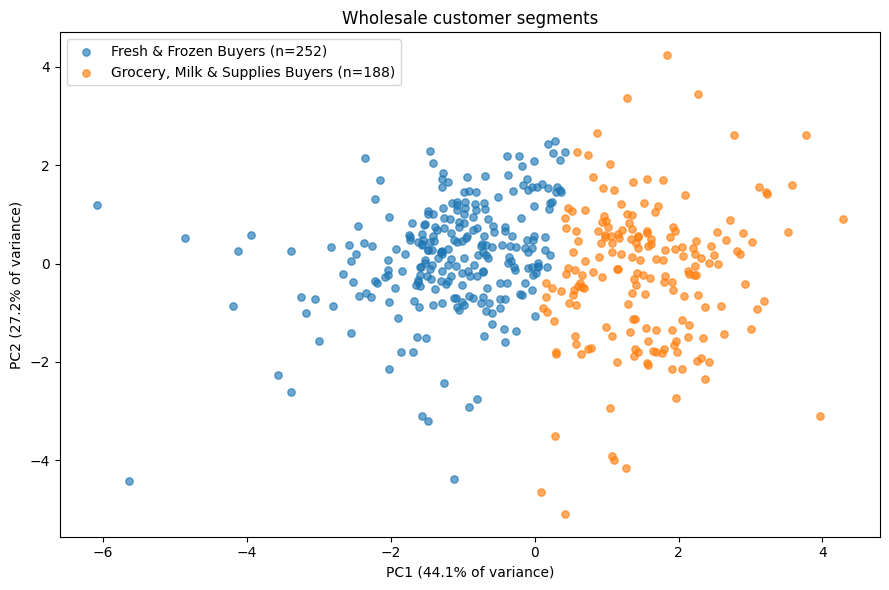

In [5]:
from sklearn.decomposition import PCA

segment_profiles = cluster_sizes.copy()
segment_profiles["Segment"] = [
    "Fresh & Frozen Buyers",
    "Grocery, Milk & Supplies Buyers",
]
segment_profiles["Purchasing characteristics"] = [
    "Higher median spending on fresh and frozen products.",
    "Higher median spending on grocery, milk, detergents, and paper products.",
]
segment_profiles["Proposed offer"] = [
    "Volume discount on a combined fresh and frozen order.",
    "Bundle discount on grocery, milk, detergents, and paper products.",
]

display(segment_profiles[
    ["Segment", "Customers", "Share", "Purchasing characteristics", "Proposed offer"]
].style.format({"Share": "{:.1%}"}))

pca = PCA(n_components=2)
pca_coordinates = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(9, 6))

for cluster_id, profile in segment_profiles.iterrows():
    mask = selected_labels == cluster_id
    ax.scatter(
        pca_coordinates[mask, 0],
        pca_coordinates[mask, 1],
        label=f"{profile['Segment']} (n={profile['Customers']})",
        alpha=0.65,
        s=28,
    )

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.set_title("Wholesale customer segments")
ax.legend()
fig.tight_layout()
plt.show()

## Questions for Management

1. **What makes each segment different?**  
   The first segment spends more on fresh and frozen products. The second
   spends more on grocery, milk, detergents, and paper products, based on
   median annual spending.

2. **Are any clusters unusually small?**  
   The two clusters contain 252 customers (57.3%) and 188 customers
   (42.7%). Both represent substantial shares of the customer base.

3. **Is the highest-scoring solution easy to interpret?**  
   Yes. K-Means with two clusters achieved the highest Silhouette Score
   (0.2903), and the median spending profiles show clear differences.
   The score also suggests the groups are only modestly separated.

4. **How would we test the offers?**  
   Within each segment, randomly assign customers to receive either the
   proposed offer or the usual offer. Compare purchase rates and gross
   profit per customer over the same period.

5. **Why is accuracy unsuitable?**  
   The dataset has no known segment labels. Silhouette Score and
   Davies–Bouldin Index evaluate the structure of the groups using
   distances between customers.

## Limitations

The segments summarize annual spending and can hide differences between
individual customers. The PCA plot shows only two dimensions of the
six-feature data. The proposed offers should be tested to find out
whether they improve sales or profit.